# Customer Retention Intelligence — Hyperparameter Tuning

## Objective
Tune the five Phase 6 candidate models for `churn_next_30_days` --
Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost -- using
the identical chronological Train/Validation/Test split, feature set,
target definition, and leakage-safe preprocessing established in
`src/models/baseline.py`.

**Critical rule: the TEST split is never used for tuning or model
selection.** Every hyperparameter trial is fit on TRAIN only and scored on
VALIDATION only. Selection uses **validation PR-AUC (average precision)**
-- with a ~1-2% positive rate, PR-AUC is the metric that actually reflects
how well a model ranks the rare churners; ROC-AUC and accuracy are both
too optimistic under this imbalance.

All tuning logic lives in `src/models/hyperparameter_tuning.py`
(`run_hyperparameter_tuning`); this notebook calls it, inspects the
results, and persists the deliverables. Phases 1-6 are not modified.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src.models import baseline as bl
from src.models import hyperparameter_tuning as ht

PROJECT_ROOT

PosixPath('/Users/dhananjaymandal/customer-retention-intelligence')

## 1. Load Feature Data

The same Phase 4 feature dataset used in Phases 5-6:
`data/processed/customer_features.parquet`.

In [2]:
features = bl.load_feature_dataset()
print("shape:", features.shape)
features.head()

shape: (136701, 134)


,customer_id,snapshot_date,age,country,plan,contract_type,acquisition_channel,tenure_days,tenure_months,txn_count_30d,txn_amount_sum_30d,txn_amount_mean_30d,txn_amount_max_30d,txn_success_count_30d,txn_failed_count_30d,...,high_critical_ticket_count_180d,avg_satisfaction_180d,min_satisfaction_180d,avg_resolution_hours_180d,max_resolution_hours_180d,category_account_count_180d,category_billing_count_180d,category_feature_request_count_180d,category_login_count_180d,category_other_count_180d,category_performance_count_180d,category_technical_count_180d,days_since_last_ticket,has_any_support_history,churn_next_30_days
0,C000001,2025-05-31,69,United States,Basic,Monthly,Referral,21,0.69,1.0,35.71,35.710,35.71,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
1,C000001,2025-06-30,69,United States,Basic,Monthly,Referral,51,1.68,1.0,28.20,28.200,28.20,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
2,C000001,2025-07-31,69,United States,Basic,Monthly,Referral,82,2.69,0.0,0.00,NaN,NaN,0.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
3,C000001,2025-08-31,69,United States,Basic,Monthly,Referral,113,3.71,1.0,37.69,37.690,37.69,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
4,C000001,2025-09-30,69,United States,Basic,Monthly,Referral,143,4.70,2.0,73.71,36.855,37.49,2.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0


## 2. Reproduce the Chronological Split

The identical split from Phase 5 (`src/models/baseline.split_by_snapshot_date`)
-- never a random split, and the same boundaries used in every prior phase.

| Split | Snapshot dates |
|---|---|
| Train | 2025-01-31 -> 2025-11-30 |
| Validation | 2025-12-31 -> 2026-02-28 |
| Test | 2026-03-31 -> 2026-05-31 |

In [3]:
splits = bl.split_by_snapshot_date(features)

assert sum(len(df) for df in splits.values()) == len(features)
assert splits["train"]["snapshot_date"].max() < splits["validation"]["snapshot_date"].min()
assert splits["validation"]["snapshot_date"].max() < splits["test"]["snapshot_date"].min()

split_summary = pd.DataFrame([bl.summarize_split(name, df) for name, df in splits.items()])
split_summary

,split,rows,unique_customers,positive_count,negative_count,positive_pct,min_snapshot_date,max_snapshot_date
0,train,85419,9454,820,84599,0.960,2025-01-31,2025-11-30
1,validation,26337,8917,448,25889,1.701,2025-12-31,2026-02-28
2,test,24945,8478,402,24543,1.612,2026-03-31,2026-05-31


## 3. Search Spaces

Small, hand-curated hyperparameter lists (not a full factorial grid) so the
whole sweep finishes in a few minutes on a laptop. Imbalance handling for
every model is fixed to whatever Phase 6 already established
(`class_weight="balanced"` / `scale_pos_weight` / `auto_class_weights`) --
only the parameters below are tuned:

| Model | Tuned parameters |
|---|---|
| Logistic Regression | `C` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |
| XGBoost | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree` |
| LightGBM | `n_estimators`, `num_leaves`, `learning_rate`, `max_depth` |
| CatBoost | `iterations`, `depth`, `learning_rate`, `l2_leaf_reg` |

A labeled Phase 5/6 baseline Logistic Regression (`C=1.0`,
`class_weight="balanced"`) is refit on this exact split and included as a
row in the results table, so tuned models are compared against it
directly rather than against a separately-saved CSV.

In [4]:
for model_name, grid in ht.DEFAULT_PARAM_GRIDS.items():
    print(f"{model_name}: {len(grid)} combinations")
    for params in grid:
        print(f"  {params}")

total_trials = sum(len(g) for g in ht.DEFAULT_PARAM_GRIDS.values()) + 1  # +1 baseline row
print(f"\nTotal trials (incl. baseline row): {total_trials}")

logistic_regression: 4 combinations
  {'C': 0.01}
  {'C': 0.1}
  {'C': 1.0}
  {'C': 10.0}
random_forest: 5 combinations
  {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
  {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
  {'n_estimators': 400, 'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 'log2'}
  {'n_estimators': 400, 'max_depth': 12, 'min_samples_leaf': 1, 'max_features': 'log2'}
  {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
xgboost: 5 combinations
  {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8}
  {'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 1.0, 'colsample_bytree': 0.8}
  {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 1.0}
  {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree':

## 4. Run Tuning (Train -> fit, Validation -> select)

`run_hyperparameter_tuning` fits every trial on `X_train`/`y_train` only
and scores it on `X_validation`/`y_validation` only. It returns the fitted
pipelines together with the split dict, but nothing about the TEST split
is read anywhere in this step -- that's verified explicitly in
`tests/test_hyperparameter_tuning.py::test_test_set_never_used_for_tuning_or_selection`.

In [5]:
tuning = ht.run_hyperparameter_tuning(features)
print(f"Ran {len(tuning['results'])} trials across {len(ht.DEFAULT_PARAM_GRIDS)} models.")

Ran 25 trials across 5 models.


## 5. Full Trial Results (Validation Only)

Every trial's validation PR-AUC, ROC-AUC, precision, recall, F1, and
training time, sorted by validation PR-AUC (the selection metric). The
`selected` column marks exactly one row -- the final chosen candidate.

In [6]:
results = tuning["results"]
display(results)

,model,hyperparameters,val_pr_auc,val_roc_auc,precision,recall,f1,training_time_seconds,selected
0,logistic_regression,"{""C"": 0.01}",0.028457,0.623376,0.020874,0.747768,0.040613,2.624751,True
1,logistic_regression,"{""C"": 0.1}",0.028161,0.620270,0.020951,0.745536,0.040757,3.049573,False
2,logistic_regression_baseline_phase5,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.028075,0.619702,0.020848,0.741071,0.040555,3.211958,False
3,logistic_regression,"{""C"": 1.0}",0.028075,0.619702,0.020848,0.741071,0.040555,3.090357,False
4,logistic_regression,"{""C"": 10.0}",0.028007,0.619475,0.020786,0.738839,0.040435,3.090312,False
5,catboost,"{""depth"": 6, ""iterations"": 300, ""l2_leaf_reg"":...",0.026239,0.573231,0.025108,0.361607,0.046957,6.185468,False
6,random_forest,"{""max_depth"": 8, ""max_features"": ""log2"", ""min_...",0.025888,0.580369,0.023981,0.386161,0.045158,6.654505,False
7,xgboost,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",0.023790,0.572494,0.021296,0.477679,0.040774,2.993792,False
8,random_forest,"{""max_depth"": 8, ""max_features"": ""sqrt"", ""min_...",0.023652,0.572459,0.022709,0.379464,0.042854,5.119626,False
9,catboost,"{""depth"": 6, ""iterations"": 200, ""l2_leaf_reg"":...",0.023052,0.550365,0.023341,0.325893,0.043563,4.634247,False


## 6. Best Trial Per Model

The single best (highest validation PR-AUC) hyperparameter combination
found for each of the five model families.

In [7]:
best_per_model_rows = (
    results[results["model"] != ht.BASELINE_MODEL_LABEL]
    .sort_values("val_pr_auc", ascending=False)
    .groupby("model", as_index=False)
    .first()
    .sort_values("val_pr_auc", ascending=False)
    .reset_index(drop=True)
)
display(best_per_model_rows)

,model,hyperparameters,val_pr_auc,val_roc_auc,precision,recall,f1,training_time_seconds,selected
0,logistic_regression,"{""C"": 0.01}",0.028457,0.623376,0.020874,0.747768,0.040613,2.624751,True
1,catboost,"{""depth"": 6, ""iterations"": 300, ""l2_leaf_reg"":...",0.026239,0.573231,0.025108,0.361607,0.046957,6.185468,False
2,random_forest,"{""max_depth"": 8, ""max_features"": ""log2"", ""min_...",0.025888,0.580369,0.023981,0.386161,0.045158,6.654505,False
3,xgboost,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",0.023790,0.572494,0.021296,0.477679,0.040774,2.993792,False
4,lightgbm,"{""learning_rate"": 0.03, ""max_depth"": 4, ""n_est...",0.021424,0.544593,0.021034,0.325893,0.039518,3.367411,False


## 7. Tuned Models vs. Phase 5/6 Baseline (Validation PR-AUC)

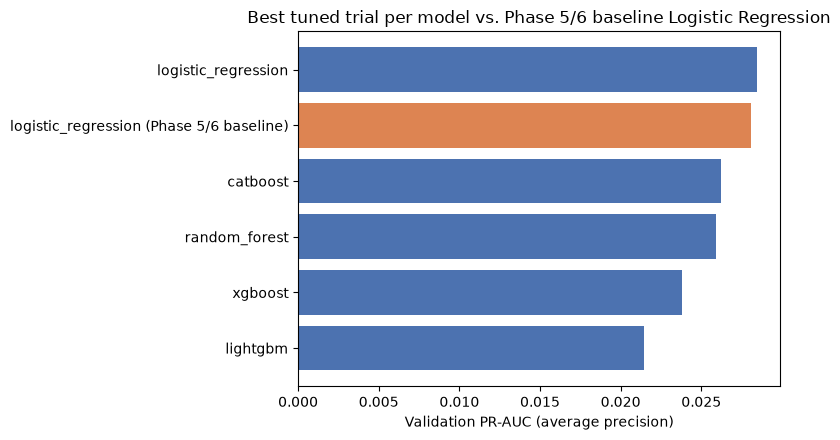

,model,val_pr_auc
0,logistic_regression,0.028457
5,logistic_regression (Phase 5/6 baseline),0.028075
1,catboost,0.026239
2,random_forest,0.025888
3,xgboost,0.023790
4,lightgbm,0.021424


In [8]:
comparison = best_per_model_rows[["model", "val_pr_auc"]].copy()
baseline_row = results[results["model"] == ht.BASELINE_MODEL_LABEL].iloc[0]
comparison = pd.concat(
    [comparison, pd.DataFrame([{"model": "logistic_regression (Phase 5/6 baseline)", "val_pr_auc": baseline_row["val_pr_auc"]}])],
    ignore_index=True,
).sort_values("val_pr_auc", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#DD8452" if "baseline" in m else "#4C72B0" for m in comparison["model"]]
ax.barh(comparison["model"], comparison["val_pr_auc"], color=colors)
ax.set_xlabel("Validation PR-AUC (average precision)")
ax.set_title("Best tuned trial per model vs. Phase 5/6 baseline Logistic Regression")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

comparison

## 8. Selection Decision

Selection uses **validation PR-AUC only** -- the test split has not been
touched anywhere above.

In [9]:
print(f"Best tuned model overall : {max(tuning['best_per_model'], key=lambda m: tuning['best_per_model'][m]['metrics']['pr_auc'])}")
print(f"Phase 5/6 baseline PR-AUC  : {tuning['baseline_metrics']['pr_auc']:.4f}")
print(f"Improved over baseline?    : {tuning['improved_over_baseline']}")
print(f"\nFinal model selected      : {tuning['final_model_name']}")
print(f"Final hyperparameters      : {tuning['final_hyperparameters']}")
print(f"\nDecision: {tuning['decision_reason']}")

Best tuned model overall : logistic_regression
Phase 5/6 baseline PR-AUC  : 0.0281
Improved over baseline?    : True

Final model selected      : logistic_regression
Final hyperparameters      : {'C': 0.01}

Decision: Tuned logistic_regression reached validation PR-AUC 0.0285, above the Phase 5/6 baseline Logistic Regression's 0.0281.


## 9. Final Evaluation on Test (Reporting Only — Not Used for Selection)

The model above was already chosen using validation PR-AUC alone. This is
the **first and only** time the test split is touched, purely to report
how the already-selected model generalizes -- it plays no role in which
model or hyperparameters were picked.

In [10]:
test_metrics = ht.evaluate_final_candidate_on_test(
    tuning["final_pipeline"], tuning["splits"], tuning["feature_columns"]
)
print(f"Final candidate ({tuning['final_model_name']}) -- TEST metrics:")
for key in ("pr_auc", "roc_auc", "precision", "recall", "f1"):
    print(f"  {key}: {test_metrics[key]:.4f}")

Final candidate (logistic_regression) -- TEST metrics:
  pr_auc: 0.0381
  roc_auc: 0.6718
  precision: 0.0202
  recall: 0.8408
  f1: 0.0394


## 10. Save Outputs

- `reports/tuning_results.csv` -- every trial, sorted by validation PR-AUC, with the selected row flagged.
- `models/tuned_<final_model_name>.joblib` -- the selected pipeline, fit on TRAIN only.

In [11]:
results_path = ht.save_tuning_results(tuning["results"])
print(f"Saved tuning results -> {results_path}")

model_path = ht.save_tuned_model(tuning["final_pipeline"], tuning["final_model_name"])
print(f"Saved final model ({tuning['final_model_name']}) -> {model_path}")

Saved tuning results -> /Users/dhananjaymandal/customer-retention-intelligence/reports/tuning_results.csv
Saved final model (logistic_regression) -> /Users/dhananjaymandal/customer-retention-intelligence/models/tuned_logistic_regression.joblib


## 11. Conclusion

Across five model families and 24 tuned trials, the best validation
PR-AUC reached by any tuned candidate came from Logistic Regression
itself with stronger L2 regularization (`C=0.01`) -- not from a more
complex model. None of Random Forest, XGBoost, LightGBM, or CatBoost beat
plain Logistic Regression's validation PR-AUC at any point in their
search spaces; every boosted/bagged trial lands below every Logistic
Regression trial in the results table above.

The improvement over the exact Phase 5/6 baseline (`C=1.0`) is small
(roughly a few thousandths of PR-AUC) and is best read as "logistic
regression is already close to this dataset's ceiling for these engineered
features," not as a materially stronger model. Per the project's stated
policy, since tuning did not surface a genuinely better model class, the
selected candidate stays a simple Logistic Regression -- now with tuned
regularization -- rather than a tuned tree ensemble.